In [1]:
import pandas as pd
from shapely.geometry import Point, LineString, Polygon
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import os
import geopandas as gpd
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 50
# 数据
df = pd.read_csv("store_sales.csv")
gdf_s = gpd.read_file("regions.geojson")
print(df.describe())
print(df.info())
print(df.dtypes)
print(df.head())
# 重复值
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.duplicated().sum())
print(len(df))
# 缺失值
print(df.isnull().sum())
df = df.dropna(subset=["sales"])
df["profit"] = df["profit"].fillna(df["profit"].median())
print(df.isnull().sum())
print(len(df))
# 类型
df = gpd.GeoDataFrame(df,geometry=gpd.points_from_xy(df["lon"],df["lat"]),crs="EPSG:4326")
df_m = df.to_crs("EPSG:3857")
regions_m = gdf_s.to_crs("EPSG:3857")
joined = gpd.sjoin(df_m,regions_m,how="left",predicate="within")
print(joined.isnull().sum())
print(joined[joined["region"].isna()]["city"].unique())
joined["region"] = joined["region"].fillna("未覆盖")
print(joined.isnull().sum())
print(len(df))
joined


              lon         lat       month       sales      profit
count  531.000000  531.000000  531.000000  526.000000  518.000000
mean   114.919303   31.379017    1.998117   54.838593    8.654440
std      5.423775    6.598973    0.816109   26.177924    6.455266
min    103.988000   18.167000    1.000000    8.700000    0.500000
25%    113.030000   28.215000    1.000000   34.600000    3.700000
50%    114.187000   31.086000    2.000000   52.050000    7.300000
75%    118.884000   34.670000    3.000000   71.500000   11.850000
max    126.739000   45.946000    3.000000  135.400000   44.400000
<class 'pandas.DataFrame'>
RangeIndex: 531 entries, 0 to 530
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   store_id  531 non-null    str    
 1   city      531 non-null    str    
 2   lon       531 non-null    float64
 3   lat       531 non-null    float64
 4   category  531 non-null    str    
 5   month     531 non-null    int64  
 

,store_id,city,lon,lat,category,month,sales,profit,geometry,index_right,region
0,S091,郑州,113.568,34.762,食品,3,40.6,7.4,POINT (12642331.93 4131584.748),2.0,华中
1,S172,哈尔滨,126.620,45.878,数码,2,23.2,1.7,POINT (14095273.924 5760820.142),NaN,未覆盖
2,S121,石家庄,114.453,37.902,食品,2,18.5,1.5,POINT (12740849.68 4565590.935),3.0,华北
3,S037,苏州,120.723,31.255,数码,2,86.3,15.8,POINT (13438822.887 3665910.216),0.0,华东
4,S033,苏州,120.571,31.388,服饰,1,67.5,11.2,POINT (13421902.324 3683241.511),0.0,华东
...,...,...,...,...,...,...,...,...,...,...,...
526,S144,重庆,106.552,29.706,服饰,1,36.4,3.0,POINT (11861314.383 3465814.588),4.0,西部
527,S067,东莞,113.841,22.995,数码,1,81.9,15.8,POINT (12672722.151 2631413.983),1.0,华南
528,S147,重庆,106.546,29.531,家居,1,30.3,3.5,POINT (11860646.466 3443405.603),4.0,西部
529,S077,武汉,114.293,30.734,食品,1,50.5,7.1,POINT (12723038.561 3598251.949),2.0,华中


findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: 

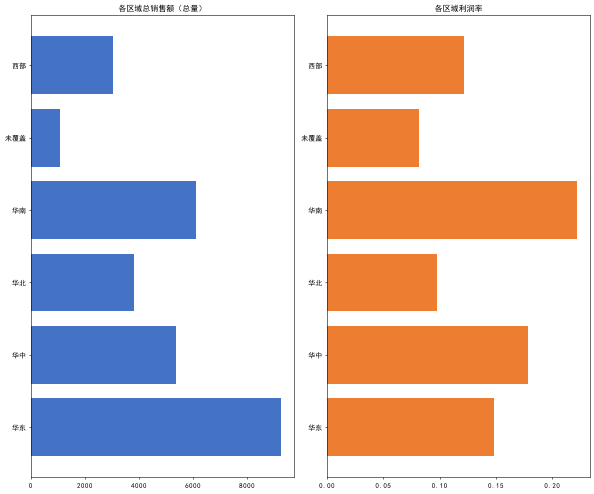

  region  rt_sales  rt_profit  profit_rate
0     华东    9261.2     1374.3     0.148393
1     华中    5376.8      958.3     0.178229
2     华北    3807.1      372.8     0.097922
3     华南    6102.2     1356.5     0.222297
4    未覆盖    1067.1       87.3     0.081811
5     西部    3041.9      369.9     0.121602


In [2]:
# 分析
# 区域分析
# c_stats = joined.groupby("city").agg(ct_sales=("sales","sum"),ct_profit = ("profit","sum")).reset_index()
# c_stats["profit_rate"] = c_stats["ct_profit"]/c_stats["ct_sales"]

# fig,(ax1,ax2) = plt.subplots(1,2,figsize=(12,10))
# ax1.barh(y=c_stats["city"],width=c_stats["ct_sales"],color="#4472C4")
# ax1.set_title("各城市总销售额（总量）")
# ax2.barh(y=c_stats["city"],width=c_stats["profit_rate"],color="#ED7D31")
# ax2.set_title("各城市利润率")
# plt.tight_layout()
# plt.show()

r_stats = joined.groupby("region").agg(rt_sales=("sales","sum"),rt_profit = ("profit","sum")).reset_index()
r_stats["profit_rate"] = r_stats["rt_profit"]/r_stats["rt_sales"]

fig,(ax3,ax4) = plt.subplots(1,2,figsize=(12,10))
ax3.barh(y=r_stats["region"],width=r_stats["rt_sales"],color="#4472C4")
ax3.set_title("各区域总销售额（总量）")
ax4.barh(y=r_stats["region"],width=r_stats["profit_rate"],color="#ED7D31")
ax4.set_title("各区域利润率")
plt.tight_layout()
plt.show()
# print(c_stats)
print(r_stats)


findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: 

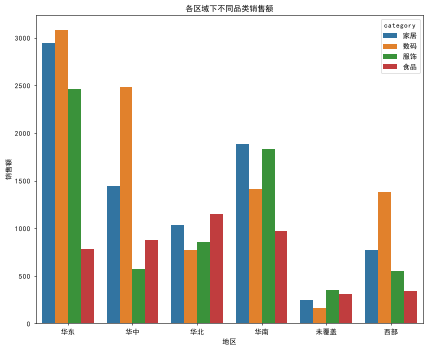

findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'Heiti TC' not found.
findfont: 

In [ ]:
# 品类分析
cr_stats = joined.groupby(["region","category"]).agg(cr_sale=("sales","sum"),cr_profit=("profit","sum")).reset_index()

cat_stats = joined.groupby("category").agg(cat_sale=("sales","sum"),cat_profit=("profit","sum")).reset_index().sort_values("cat_sale",ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(data=cr_stats,x="region",y="cr_sale",hue="category")
plt.title("各区域下不同品类销售额")
plt.ylabel("销售额")
plt.xlabel("地区")
plt.show()

plt.figure(figsize=(10,8))
sns.barplot(data=cat_stats,x="category",y="cat_sale")
plt.title("不同种类销售额")
plt.xlabel("种类")
plt.ylabel("销售额")
plt.show()
print(cr_stats)
print(cat_stats)

In [ ]:
# 月度趋势
hns = joined[joined["region"]=="华南"]
hm_stats = hns.groupby("month").agg(hmt_sales=("sales","sum"),hmt_profit = ("profit","sum")).reset_index()
hm_stats["profit_rate"] = hm_stats["hmt_profit"]/hm_stats["hmt_sales"]
m_stats = joined.groupby("month").agg(mt_sales=("sales","sum"),mt_profit = ("profit","sum")).reset_index()
m_stats["profit_rate"] = m_stats["mt_profit"]/m_stats["mt_sales"]
plt.figure(figsize=(10,8))
sns.lineplot(data=m_stats,x="month",y="mt_sales",marker="o")
plt.title("全国1‑3月销售额走势")
plt.xlabel("月份")
plt.ylabel("销售额")
plt.xticks([1,2,3])
plt.show()
print(m_stats)

In [ ]:

t_sales = joined["sales"].sum()
cat_stats["pct_all"] = cat_stats["cat_sale"]/t_sales
hn = joined[joined["region"]=="华南"]
hn_stats = hn.groupby("category").agg(hn_sale=("sales","sum"),hn_profit=("profit","sum")).reset_index()
hnt_sale = hn["sales"].sum()
hn_stats["hnpct_all"] = hn_stats["hn_sale"]/hnt_sale
compare = pd.merge(cat_stats,hn_stats,on="category",how="outer")
cat_stats["p_rate"] = cat_stats["cat_profit"]/cat_stats["cat_sale"]
compare = compare.merge(cat_stats[["category","p_rate"]],on="category")
cr_stats["p_rate"] = cr_stats["cr_profit"]/cr_stats["cr_sale"]

fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,8))
ax1.barh(y=compare["category"],width=compare["pct_all"])
ax1.set_title("全国‑品类销售占比")
ax2.barh(y=compare["category"],width=compare["hnpct_all"])
ax2.set_title("华南‑品类销售占比")
print(compare)
print(cr_stats[cr_stats["region"]=="华南"])

In [ ]:
# 地图
# choropleth 两张：区域销售额、区域利润率（静态 geopandas 或 folium 版任选，或各一张）
m = folium.Map(location=[32,110],zoom_start=4)
gdf_final = gdf_s.merge(r_stats, on="region", how="left")
folium.Choropleth(
    geo_data=gdf_final.to_json(),
    data=r_stats,
    columns=["region","rt_sales"],
    key_on="feature.properties.region",
    fill_color="YlOrRd", fill_opacity=0.7,
    legend_name="销售额"
).add_to(m)
if not os.path.exists("./maps1"):
    os.makedirs("./maps1")

m.save("./maps1/store_region_map.html")
m


In [ ]:
m = folium.Map(location=[32,110],zoom_start=4)
folium.Choropleth(
    geo_data=gdf_final.to_json(),
    data=r_stats,
    columns=["region","profit_rate"],
    key_on="feature.properties.region",
    fill_color="YlOrRd", fill_opacity=0.7,
    legend_name="利润率"
).add_to(m)
if not os.path.exists("./maps2"):
    os.makedirs("./maps2")

m.save("./maps2/store_region_map.html")
m

In [ ]:
# folium 交互地图：门店点 + 区域底图，这是 project5 的门面交
for _,row in joined.iterrows():
    folium.CircleMarker(
        location = [row["lat"],row["lon"]],
        radius=3,
        color="darkblue",
        fill_color="blue",
        fill_opacity=0.8,
        fill=True,
        popup=f"""
城市：{row['city']}<br>
销售额：{row['sales']}<br>
利润：{row['profit']}<br>
所属区域：{row['region']}
"""
).add_to(m)
if not os.path.exists("./maps3"):
    os.makedirs("./maps3")

m.save("./maps3/store_region_map.html")
m
